# What do the generators reproduce — and miss?

The first notebook separated the predictable clear-sky irradiance from the cloud factor $k(t)$. We now investigate whether simple generative models can reproduce its statistical distribution and temporal fluctuations.

We compare three approaches:

- **Historical-day bootstrap:** Resamples complete training days, preserving measured fluctuations without generating new weather profiles.
- **Probabilistic PCA (PPCA):** Models daily cloud-factor profiles using eight latent variables, with or without independent Gaussian residual noise.
- **Variational autoencoder (VAE):** A small neural-network generator with eight latent variables and a variance-matched training objective.

All models were fitted on **2020–2023**, validated on **2024**, and evaluated with frozen configurations on **2025**. Each ensemble contains 365 days.

The bootstrap retains each sampled training day's cloud conditions and solar geometry. PPCA and VAE instead combine generated cloud factors with clear-sky references from randomly selected 2025 dates. Comparisons of reconstructed irradiance and daily energy are therefore not exactly geometry-matched.


In [1]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt

assets_dir = Path("assets")
if not (assets_dir / "final_2025_summary.json").exists():
    assets_dir = Path("notebooks/assets")

with (assets_dir / "final_2025_summary.json").open() as f:
    report = json.load(f)

summary = report["collections"]

# Use the same colors throughout this notebook.
methods = [
    ("observed_2025", "Observed 2025", "tab:blue"),
    ("bootstrap", "Bootstrap (train days)", "tab:orange"),
    ("ppca_q8", "PPCA, q=8", "tab:green"),
    ("ppca_q8_with_noise", "PPCA + residual", "tab:red"),
    ("vae_variance_matched", "VAE (variance-matched)", "tab:purple"),
]

print(f"Held-out test: 2025 ({report['n_test_days']} days)")
print(f"Random seed: {report['frozen_configurations']['seed']}")
print(f"Collections: {len(summary)}")

Held-out test: 2025 (365 days)
Random seed: 0
Collections: 5


## Reproducing short-time fluctuations

A realistic distribution of irradiance values does not necessarily imply realistic temporal behaviour. We examine two measures:

- **Ten-minute ramp magnitude:** The absolute irradiance change $|\Delta G|=|G(t+10\,\mathrm{min})-G(t)|$. Its 95th percentile (p95) characterizes relatively large fluctuations.
- **Autocorrelation:** The correlation of the cloud factor $k$ at increasing time lags, indicating how strongly its values persist over time.

Both measures use valid daylight observations within individual days. Ramps require adjacent valid slots; autocorrelation uses valid pairs separated by the specified lag.


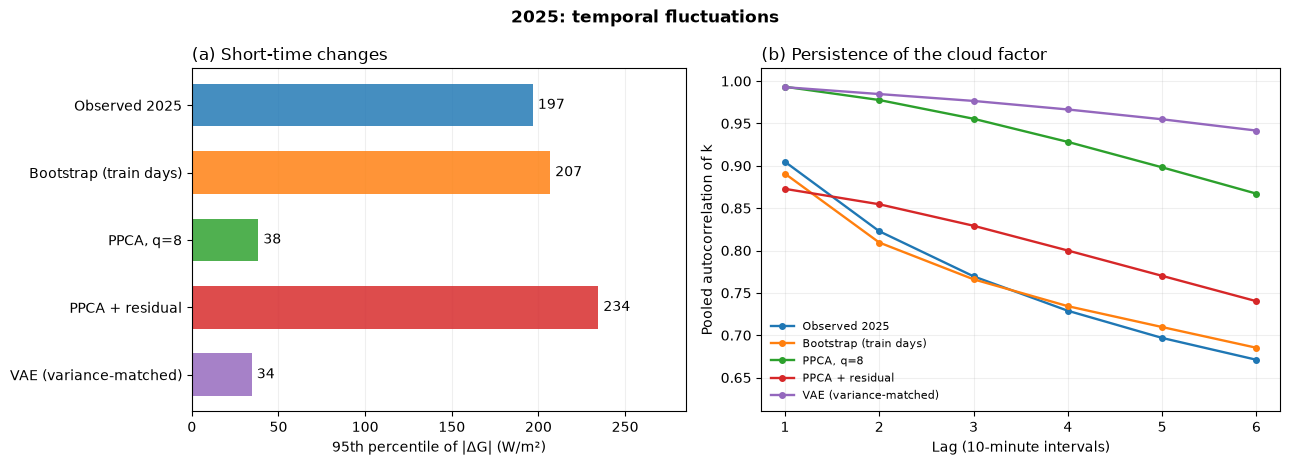

In [2]:
fig, (ax_ramp, ax_corr) = plt.subplots(
    1, 2,
    figsize=(13, 4.7),
    gridspec_kw={"width_ratios": [1, 1.05]},
)

# Left: upper tail of ten-minute irradiance changes.
positions = np.arange(len(methods))[::-1]
ramps = [
    summary[key]["abs_ramp_wm2_per_slot"]["p95"]
    for key, _, _ in methods
]

for pos, value, (_, label, color) in zip(
    positions, ramps, methods
):
    ax_ramp.barh(
        pos, value, height=0.63,
        color=color, alpha=0.83
    )
    ax_ramp.text(
        value + 3, pos, f"{value:.0f}",
        va="center", fontsize=10
    )

ax_ramp.set_yticks(
    positions, [label for _, label, _ in methods]
)
ax_ramp.set_xlim(0, 285)
ax_ramp.set_xlabel("95th percentile of |ΔG| (W/m²)")
ax_ramp.set_title("(a) Short-time changes", loc="left")
ax_ramp.grid(axis="x", alpha=0.2)
ax_ramp.set_axisbelow(True)

# Right: correlation across lags of 10 to 60 minutes.
lags = np.arange(1, 7)

for key, label, color in methods:
    acf = summary[key]["autocorrelation_k"]
    values = [acf[str(lag)] for lag in lags]
    ax_corr.plot(
        lags, values,
        color=color, marker="o",
        markersize=4, linewidth=1.7,
        label=label
    )

ax_corr.set_xlabel("Lag (10-minute intervals)")
ax_corr.set_ylabel("Pooled autocorrelation of k")
ax_corr.set_ylim(0.61, 1.015)
ax_corr.set_xticks(lags)
ax_corr.set_title(
    "(b) Persistence of the cloud factor", loc="left"
)
ax_corr.grid(alpha=0.2)
ax_corr.legend(
    loc="lower left", fontsize=8, frameon=False
)

fig.suptitle(
    "2025: temporal fluctuations",
    fontweight="bold"
)
fig.tight_layout()
plt.show()

**Figure 1. Temporal variability of observed and generated irradiance.** (a) The 95th percentile of absolute ten-minute GHI changes, calculated between consecutive valid daylight measurements. (b) Cloud-factor autocorrelation at lags of 10–60 minutes. The tested PPCA and VAE configurations underestimate rapid fluctuations and show excessive persistence. Adding Gaussian residual noise to PPCA restores approximate ramp magnitudes but not the observed temporal correlations.


Observed irradiance has a ten-minute ramp p95 of approximately **197 W/m²**, compared with **38 W/m²** for PPCA and **34 W/m²** for the VAE. Their high autocorrelations also indicate overly smooth generated profiles.

The bootstrap agrees much more closely with observation, as expected from resampling measured days.

Adding independent Gaussian noise raises PPCA's ramp p95 to **234 W/m²**, but its autocorrelation is lower than observed at 10 minutes and higher at subsequent lags. Thus, restoring fluctuation magnitudes does not necessarily reproduce their temporal structure.


## How does variability differ from day to day?

Figure 1 summarizes fluctuations across each complete ensemble, but individual days can be much calmer or more variable than others.

To examine this variation, we calculate the 95th-percentile ten-minute irradiance change for each day separately. The resulting distribution shows how frequently each model produces days with weak or strong fluctuations.


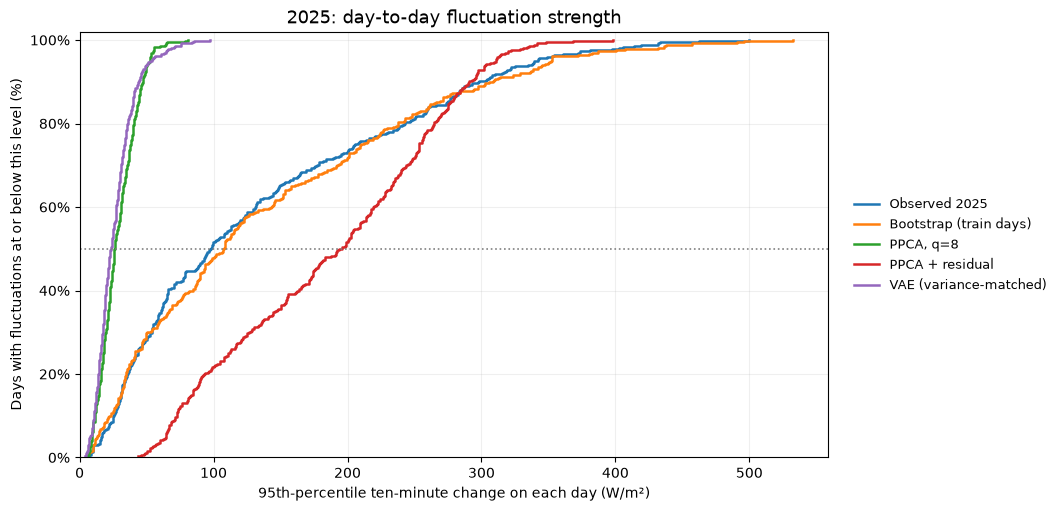

In [3]:
from matplotlib.ticker import PercentFormatter

profile_path = assets_dir / "final_2025_profiles.npz"

with np.load(profile_path, allow_pickle=False) as archive:
    profiles = {
        key: {
            field: archive[f"{key}__{field}"]
            for field in ("dates", "k", "valid", "g_clear_cal")
        }
        for key, _, _ in methods
    }


def daily_ramp_p95(data):
    """Calculate the ramp p95 separately for each day."""
    valid = data["valid"]
    ghi = data["k"] * data["g_clear_cal"]

    changes = np.abs(np.diff(ghi, axis=1))
    valid_pairs = valid[:, :-1] & valid[:, 1:]

    results = []
    for i in range(len(ghi)):
        ramps = changes[i, valid_pairs[i]]
        results.append(
            np.percentile(ramps, 95) if ramps.size else np.nan
        )

    return np.asarray(results)


fig, ax = plt.subplots(
    figsize=(10.5, 5),
    layout="constrained"
)

for key, label, color in methods:
    values = daily_ramp_p95(profiles[key])
    assert np.all(np.isfinite(values))

    sorted_values = np.sort(values)
    cumulative = (
        np.arange(1, len(sorted_values) + 1)
        / len(sorted_values)
    )

    ax.step(
        sorted_values,
        cumulative,
        where="post",
        color=color,
        linewidth=1.8,
        label=label,
    )

# The 50% level identifies the median of daily ramp p95 values.
ax.axhline(
    0.5,
    color="0.5",
    linestyle=":",
    linewidth=1.2
)

ax.set_xlabel(
    "95th-percentile ten-minute change on each day (W/m²)"
)
ax.set_ylabel(
    "Days with fluctuations at or below this level (%)"
)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.set_xlim(left=0)
ax.set_ylim(0, 1.02)
ax.set_title(
    "2025: day-to-day fluctuation strength",
    fontsize=13
)

ax.grid(alpha=0.2)
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=9
)

plt.show()

**Figure 2. Distribution of daily irradiance fluctuations.** For each of the 365 days in each collection, the 95th percentile of absolute ten-minute GHI changes is calculated from consecutive valid daylight measurements. Each curve shows the percentage of days whose daily ramp p95 is at or below the indicated value. The horizontal 50% line identifies the medians. Unlike the pooled statistic in Figure 1, this comparison reveals how fluctuation strength varies between days. The bootstrap retains training-year solar geometry, while PPCA and VAE use sampled 2025 reference dates.


The observed and bootstrap distributions are similar, spanning a broad range of daily fluctuation strengths. In contrast, PPCA and VAE produce predominantly smooth days, with much smaller ten-minute changes.

Adding Gaussian residual noise increases PPCA's daily fluctuations, but the resulting distribution still differs from observation. Thus, even though its pooled ramp p95 is close to the observed value (Figure 1), it does not reproduce the same variation between days.


## Reproducing irradiance distributions

We also examine whether the models reproduce the distribution of irradiance conditions, rather than only their temporal behaviour:

- **Cloud factor:** The frequency of different $k$ values across valid daylight slots, including negative generated values and values above one.
- **Daily irradiation:** The accumulated solar energy per unit area, expressed in kWh/m².

The first describes individual values without their temporal ordering; the second summarizes the total energy received over a day.

The bootstrap's daily irradiation retains training-year solar geometry, so its comparison with the 2025 observations is not exactly geometry-matched.


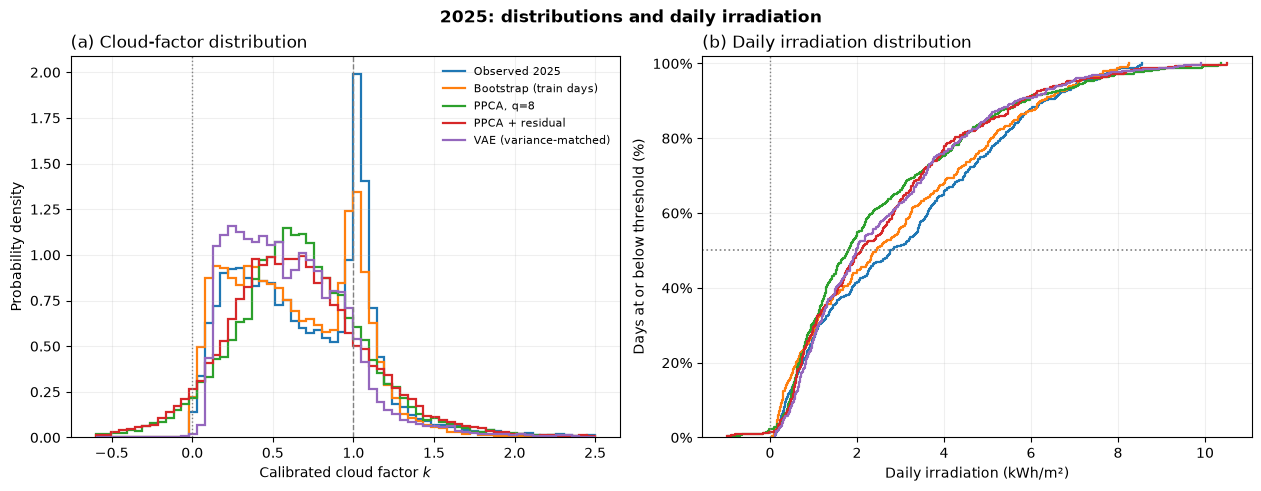

In [4]:
from matplotlib.ticker import PercentFormatter

fig, (ax_k, ax_energy) = plt.subplots(
    1, 2, figsize=(12.5, 4.8),
    layout="constrained"
)

bins = np.linspace(-0.6, 2.5, 65)

for key, label, color in methods:
    data = profiles[key]
    valid = data["valid"]

    # Normalize using all valid slots, including values outside
    # the displayed histogram range.
    k = data["k"][valid]
    counts, _ = np.histogram(k, bins=bins)
    density = counts / (len(k) * np.diff(bins))

    ax_k.stairs(
        density, bins,
        color=color, linewidth=1.6,
        label=label
    )

    # GHI in W/m², integrated over 600-second intervals.
    ghi = np.where(
        valid,
        data["k"] * data["g_clear_cal"],
        0.0
    )
    daily_energy = ghi.sum(axis=1) / 6000  # kWh/m²

    # Check against the frozen evaluation summary.
    expected = summary[key]["daily_energy_kwh_m2"]["median"]
    assert np.isclose(
        np.median(daily_energy), expected,
        rtol=1e-5, atol=1e-5
    )

    energy_sorted = np.sort(daily_energy)
    cdf = np.arange(1, len(energy_sorted) + 1) / len(energy_sorted)

    ax_energy.step(
        energy_sorted, cdf,
        where="post", color=color, linewidth=1.6
    )

# (a) Cloud-factor distributions
ax_k.axvline(0, color="0.5", linestyle=":", linewidth=1)
ax_k.axvline(1, color="0.5", linestyle="--", linewidth=1)
ax_k.set_xlabel("Calibrated cloud factor $k$")
ax_k.set_ylabel("Probability density")
ax_k.set_title("(a) Cloud-factor distribution", loc="left")
ax_k.legend(fontsize=8, frameon=False)
ax_k.grid(alpha=0.2)

# (b) Cumulative distribution of daily irradiation
ax_energy.axvline(
    0, color="0.5", linestyle=":", linewidth=1
)
ax_energy.axhline(
    0.5, color="0.5", linestyle=":", linewidth=1.2
)

ax_energy.set_xlabel("Daily irradiation (kWh/m²)")
ax_energy.set_ylabel("Days at or below threshold (%)")
ax_energy.yaxis.set_major_formatter(PercentFormatter(1.0))
ax_energy.set_ylim(0, 1.02)
ax_energy.set_title("(b) Daily irradiation distribution", loc="left")
ax_energy.grid(alpha=0.2)

fig.suptitle(
    "2025: distributions and daily irradiation",
    fontweight="bold"
)

plt.show()

**Figure 3. Cloud-factor and daily-irradiation distributions.** (a) Probability density of the calibrated cloud factor $k$ across valid daylight slots, displayed for $-0.6\leq k\leq2.5$. (b) Cumulative distribution of daily irradiation in kWh/m². Each curve shows the percentage of days receiving at most the indicated energy; the 50% line identifies the medians. Negative generated values are not clipped. The bootstrap retains training-year solar geometry, unlike PPCA and VAE.


The observed 2025 cloud-factor distribution has a pronounced peak near $k=1$, which none of the generated distributions fully reproduces. The fraction with $k>1$ is **29.7%** in observations, compared with **21.5%** for bootstrap, **18.3%** for PPCA, and **12.1%** for VAE.

PPCA also generates nonphysical negative cloud factors (**4.9%**, or **5.7%** with residual noise). The VAE largely avoids these (**0.1%**) but still underestimates higher cloud factors.

Median daily irradiation is **2.76 kWh/m²** in observations, versus **2.44** for bootstrap, **1.79** for PPCA, **2.08** for noisy PPCA, and **1.97** for VAE. These differences reflect both cloud-factor distributions and assigned solar geometry. In particular, the bootstrap reproduces training-period weather, which need not match the sunnier 2025 observations.


## Examples of generated solar irradiance

To illustrate the models' output in physical units, we compare one observed July 2025 profile with synthetic examples from PPCA, PPCA with residual noise, and VAE.

All four panels use the same calibrated clear-sky reference, keeping solar geometry fixed. The synthetic profiles are independent realizations, not forecasts of the observed weather. Their purpose is illustration. The statistical comparisons above provide the quantitative evaluation.


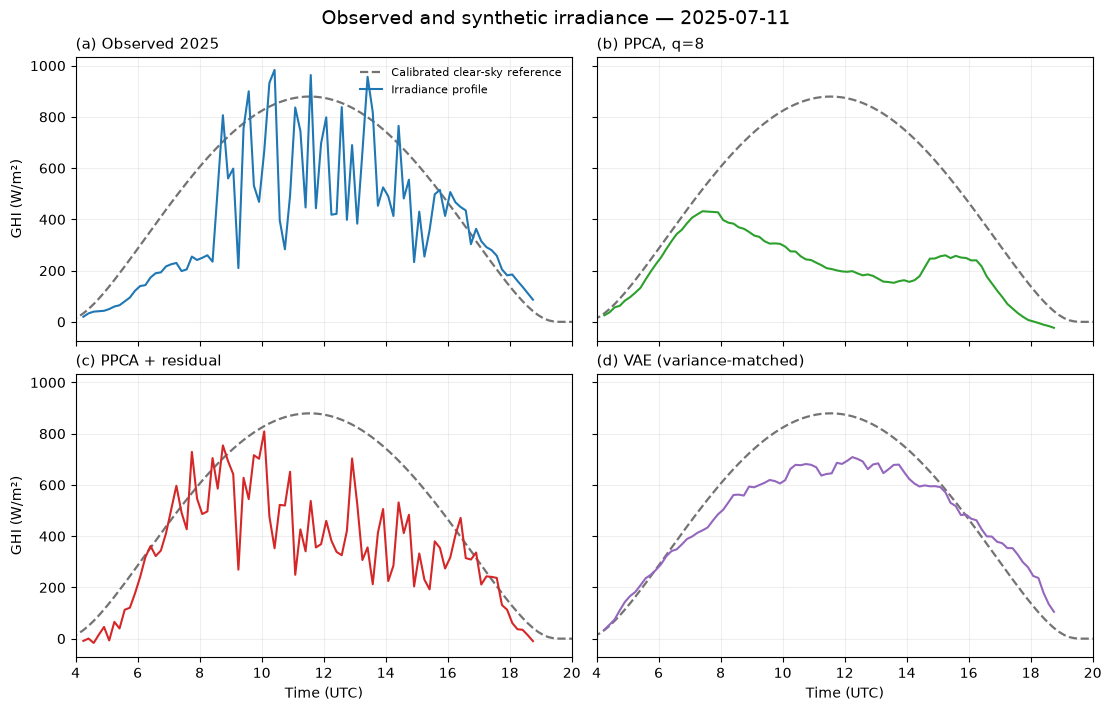

In [5]:
panel_keys = [
    "observed_2025",
    "ppca_q8",
    "ppca_q8_with_noise",
    "vae_variance_matched",
]

method_style = {
    key: (label, color)
    for key, label, color in methods
}


def july_dates(data):
    """Return unique July reference dates in a collection."""
    dates = data["dates"].astype("datetime64[D]")
    months = dates.astype("datetime64[M]").astype(int) % 12 + 1
    return np.unique(dates[months == 7])


# Find a July reference date present in all four collections.
common_dates = july_dates(profiles[panel_keys[0]])

for key in panel_keys[1:]:
    common_dates = np.intersect1d(
        common_dates, july_dates(profiles[key])
    )

if not len(common_dates):
    raise ValueError(
        "No common July reference date in the frozen ensembles."
    )

# Deterministic selection, independent of profile appearance.
reference_date = common_dates[0]

hours = (np.arange(144) * 10 + 5) / 60
panel_labels = ["(a)", "(b)", "(c)", "(d)"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7),
    sharex=True,
    sharey=True,
    layout="constrained",
)

# Verify that all panels share the same clear-sky reference.
shared_reference = None

for ax, key, panel_label in zip(
    axes.flat, panel_keys, panel_labels
):
    data = profiles[key]
    label, color = method_style[key]

    dates = data["dates"].astype("datetime64[D]")
    i = np.flatnonzero(dates == reference_date)[0]

    reference = data["g_clear_cal"][i]
    valid = data["valid"][i]

    if shared_reference is None:
        shared_reference = reference.copy()
    else:
        assert np.allclose(
            reference, shared_reference,
            equal_nan=True
        ), "Clear-sky references differ for the same date"

    ghi = np.where(
        valid,
        data["k"][i] * reference,
        np.nan
    )

    ax.plot(
        hours, reference,
        color="0.45",
        linestyle="--",
        linewidth=1.6,
        label="Calibrated clear-sky reference",
    )
    ax.plot(
        hours, ghi,
        color=color,
        linewidth=1.5,
        label="Irradiance profile",
    )

    ax.set_title(
        f"{panel_label} {label}",
        loc="left",
        fontsize=11,
    )
    ax.grid(alpha=0.2)
    ax.set_xlim(4, 20)
    ax.set_xticks(np.arange(4, 21, 2))

for ax in axes[:, 0]:
    ax.set_ylabel("GHI (W/m²)")

for ax in axes[-1]:
    ax.set_xlabel("Time (UTC)")

axes[0, 0].legend(
    frameon=False,
    fontsize=8,
    loc="upper right",
)

fig.suptitle(
    f"Observed and synthetic irradiance — {reference_date}",
    fontsize=14,
)

plt.show()


**Figure 4. Observed and synthetic irradiance under common solar geometry.** (a) Observed GHI, (b) PPCA, (c) PPCA with Gaussian residual noise, and (d) VAE. Solid curves show observed or generated irradiance; dashed curves show their common calibrated clear-sky reference. The earliest July 2025 date shared by all collections is selected, using the first sample when a date occurs more than once. The generated profiles are independent realizations, not weather forecasts. Bootstrap is omitted because it resamples historical measurements.


## What changed between 2024 and 2025?

The observed cloud-factor distribution changed between validation (2024) and testing (2025), while two measures of temporal variability remained similar.

| Observed quantity | 2024 (validation) | 2025 (test) |
|---|---:|---:|
| Median cloud factor $k$ | 0.584 | 0.678 |
| Fraction with $k>1$ | 21.6% | 29.7% |
| 95th percentile of $|\Delta G|$ (W/m²) | 197 | 197 |
| Lag-1 autocorrelation of $k$ | 0.903 | 0.905 |

*The 2024 values come from the validation evaluation; the 2025 values from the frozen final evaluation.*

The higher median $k$ indicates more irradiance relative to the clear-sky reference in 2025. Yet ramp p95 and lag-1 autocorrelation were almost unchanged. This does not establish year-invariant dynamics, but shows that the models' oversmoothing was not confined to the validation year.

## Conclusion

SkyFlux illustrates the distinction between reproducing how irradiance values are distributed and how they evolve in time.

Historical-day bootstrap preserves measured fluctuations but cannot generate novel weather patterns. The tested PPCA and VAE models generate new profiles but strongly underestimate short-time variability. Adding independent noise to PPCA restores ramp magnitudes without reproducing the observed temporal behaviour.

The results highlight the importance of evaluating temporal structure alongside marginal distributions. They characterize the tested configurations, not fundamental limitations of PPCA or VAEs.
